# Global / Regional / Zonal Average Timeseries Plots

Makes spin up and parameter implementation spaghetti plots

In [11]:
# Data-path configuration (see ../paths.py and ../DATA.md).
# Set SCREAM_AUTOTUNE_HPSS / SCREAM_AUTOTUNE_ZENODO to point at your data;
# assumes this notebook is run from its own directory (the Jupyter default).
import os, sys, glob, datetime
sys.path.insert(0, os.path.abspath(".."))
import paths
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.cm as cm

## Locally replace `hapy` 

In [5]:
class tclr:
   GREEN='\033[92m'; CYAN='\033[96m'; YELLOW='\033[93m'; MAGENTA='\033[95m'; END='\033[0m'

def fill_color_list(clr, cmap='rainbow', randomize=True):
   """Fill any None entries in `clr` with colors sampled from a matplotlib colormap."""
   n = len(clr)
   cmap_obj = matplotlib.colormaps.get_cmap(cmap if cmap else 'tab20')
   idx = np.linspace(0, 1, n)
   if randomize:
      rng = np.random.default_rng(0)
      idx = rng.permutation(idx)
   sampled = [cmap_obj(i) for i in idx]
   return [c if c is not None else sampled[i] for i, c in enumerate(clr)]

def print_stat(data, name='', compact=True, indent=''):
   d = np.asarray(data)
   print(f'{indent}{name}: min={np.nanmin(d):.4g}  max={np.nanmax(d):.4g}  mean={np.nanmean(d):.4g}')

def dash_to_linestyle(d):
   return {0:'-', 1:'--', 2:':', 3:'-.'}.get(d, '-')


## Load in and average

In [2]:
lat_bands = np.linspace(-90, 90, 19)  # 18 zones, 10 degree bands
regions_list = ['poles', 'extratropical_land', 'extratropical_ocean',
                 'tropical_land', 'ascending_tropical_ocean', 'descending_tropical_ocean']

def zonal_means_native(data, area, lat, lon):
   data = np.asarray(data).squeeze()
   masked_area = np.where(np.isnan(data), np.nan, area).squeeze()
   lat = np.asarray(lat).squeeze()
   zonal_means = dict()
   for i in range(len(lat_bands) - 1):
      mask_zone = (lat >= lat_bands[i]) & (lat < lat_bands[i+1])
      data_zone = np.where(mask_zone, data, np.nan)
      area_zone = np.where(mask_zone, masked_area, np.nan)
      zone_center = lat_bands[i] + (lat_bands[i+1] - lat_bands[i]) / 2
      if np.all(np.isnan(data_zone)) or np.nansum(area_zone) == 0:
         zonal_means[zone_center] = np.nan
      else:
         zonal_means[zone_center] = np.nansum(data_zone * area_zone) / np.nansum(area_zone)
   return zonal_means

def regional_means_native(data, area, region_data):
   data = np.asarray(data).squeeze()
   masked_area = np.where(np.isnan(data), np.nan, area).squeeze()
   region_means = dict()
   for reg_name in regions_list:
      mask_reg = np.asarray(region_data[reg_name]).squeeze()
      data_reg = np.where(mask_reg > 0, data, np.nan)
      area_reg = np.where(mask_reg > 0, masked_area, np.nan)
      if np.all(np.isnan(data_reg)) or np.nansum(area_reg) == 0:
         region_means[reg_name] = np.nan
      else:
         region_means[reg_name] = np.nansum(data_reg * area_reg) / np.nansum(area_reg)
   return region_means

def global_means_native(data, area):
   data = np.asarray(data).squeeze()
   masked_area = np.where(np.isnan(data), np.nan, area).squeeze()
   return np.nansum(data * masked_area) / np.nansum(masked_area)


In [3]:
case_name, case, case_dir, case_sub = [], [], [], []
clr, dsh, mrk = [], [], []
lwd = []

def add_case(case_in, n='', p=None, s='', d=0, c=None, m=0, lw=None):
   case.append(case_in); case_name.append(n)
   case_dir.append(p); case_sub.append(s)
   dsh.append(d); clr.append(c); mrk.append(m); lwd.append(lw)

var, var_str, file_type_list, lev_list, unit_fac_list = [], [], [], [], []

def add_var(var_name, file_type, name=None, unit='', lev=None, unit_fac=None):
   var.append(var_name)
   file_type_list.append(file_type)
   var_str.append(var_name if name is None else name)
   lev_list.append(lev)
   unit_fac_list.append(unit_fac)


In [25]:
tmp_scratch = str(paths.DY1_DIR)  # DY1 PPE members (HPSS): dy1/m0000 … dy1/m0152
tmp_sub = 'SCREAM.2024-autocal-00.ne1024pg2/run'
tmp_file_type = 'output.scream.AutoCal.hourly_inst_ne30pg2.INSTANT.nhours_x1.'

# 'seed' = the spin-up run (drawn as one thick black line, full time range)
add_case('seed', n='Spin Up', c='black', lw=2.5, p=tmp_scratch, s=tmp_sub)

# PPE members = the swarm of thin colored lines (only their first 2 output
# files are used - see get_file_list - since each member only ran 2 days).
# Register everyone here - exclude/re-include specific labels later in the
# "Exclude / re-include runs" cell, which doesn't require reloading.
ppe_params = pd.read_json(str(paths.PPE_PARAMS_JSON))
for label in ppe_params.index:
   add_case(label, p=tmp_scratch, s=tmp_sub, lw=1.2)

clr = fill_color_list(clr, cmap='tab20', randomize=True)

add_var('Total Liquid Water Path', tmp_file_type, name='TLWP (kg/m$^2$)')


In [8]:
grid_ref_file = str(paths.DY1_DIR / 'm0000' / tmp_sub / 'output.scream.AutoCal.daily_avg_ne30pg2.AVERAGE.nhours_x24.2016-08-07-00000.nc')
regions_file_path = str(paths.REGIONS_FILE)

grid_ref = xr.open_dataset(grid_ref_file)
area = grid_ref['area'].values
lat = grid_ref['lat'].values
lon = grid_ref['lon'].values
regions_file = xr.open_dataset(regions_file_path)


In [9]:
fig_dir = str(paths.FIGURES_DIR)
fig_type = 'png'
os.makedirs(fig_dir, exist_ok=True)

label_font_size = 12
title_font_size = 14
line_thickness = 1.5

def get_file_list(tcase, tcase_dir, tcase_sub, tfile_type):
   file_path = f'{tcase_dir}/{tcase}/{tcase_sub}/*{tfile_type}*'
   file_list = sorted(glob.glob(file_path))
   if file_list == []:
      print(f'ERROR: Empty file list:\n{file_path}')
      return []
   # 'seed' is the multi-day spin-up run (all its files are used); every other
   # case is a 2-day PPE member run, so only its first 2 files are used - this
   # is why the reference plot shows one long black line (seed, ~5 days) and a
   # swarm of colored lines only over the last ~2 days (the PPE members).
   if tcase != 'seed':
      file_list = file_list[:2]
   elif len(file_list) > 2:
      file_list = file_list[:len(file_list)-1]  # skip last (possibly incomplete) file
   return file_list

def cftime_to_pydatetime(tval):
   """Convert a cftime object (e.g. DatetimeNoLeap) or numpy/pandas datetime to a
   plain python datetime.datetime, since pandas.Timestamp can't parse cftime types
   directly (non-standard calendars like 'noleap' used in many E3SM/SCREAM outputs)."""
   if hasattr(tval, 'year') and hasattr(tval, 'calendar'):
      return datetime.datetime(tval.year, tval.month, tval.day, tval.hour, tval.minute, tval.second)
   return pd.Timestamp(tval).to_pydatetime()


## Process data

In [ ]:
num_case, num_var = len(case), len(var)

date_list_all, global_list_all, regional_list_all, zonal_list_all = {}, {}, {}, {}

for v in range(num_var):
   tvar = var[v]
   print(tclr.GREEN + f'var: {tvar}' + tclr.END)

   date_list, global_list, regional_list, zonal_list = [], [], [], []

   for c in range(num_case):
      print(' ' * 2 + tclr.CYAN + f'case: {case[c]}' + tclr.END)
      file_list = get_file_list(case[c], case_dir[c], case_sub[c], file_type_list[v])
      if not file_list:
         date_list.append(np.array([])); global_list.append(np.array([]))
         regional_list.append(pd.DataFrame()); zonal_list.append(pd.DataFrame())
         continue

      dates, gmeans, rmeans, zmeans = [], [], [], []
      for f, fpath in enumerate(file_list):
         print(' ' * 4 + f'f:{f:03d}  {tclr.YELLOW}{fpath}{tclr.END}')
         ds = xr.open_dataset(fpath)
         data = ds[tvar]
         if 'lev' in data.dims and lev_list[v] is not None:
            data = data.isel(lev=abs(lev_list[v]))
         if unit_fac_list[v] is not None:
            data = data * unit_fac_list[v]

         ntime = data.sizes.get('time', 1)
         for t in range(ntime):
            dslice = data.isel(time=t) if 'time' in data.dims else data
            tval = ds['time'].values[t] if 'time' in ds['time'].dims else ds['time'].values
            dates.append(cftime_to_pydatetime(tval))
            gmeans.append(global_means_native(dslice.values, area))
            rmeans.append(regional_means_native(dslice.values, area, regions_file))
            zmeans.append(zonal_means_native(dslice.values, area, lat, lon))

      date_list.append(np.array(dates))
      global_list.append(np.array(gmeans))
      regional_list.append(pd.DataFrame(rmeans))
      zonal_list.append(pd.DataFrame(zmeans))

   date_list_all[tvar] = date_list
   global_list_all[tvar] = global_list
   regional_list_all[tvar] = regional_list
   zonal_list_all[tvar] = zonal_list


## Plot

In [ ]:
exclude_ppe_labels = {'m0138', 'optmar26d'}   # remove unused runs
recolor_cmap = 'tab20'      
seed_linewidth = 2        # linewidth for the 'Spin Up'/seed line
ppe_linewidth = 1.2         # linewidth for PPE member lines
unit_rescale = 1 #1e3        
n_report_highest_start = 2

if '_case_full' not in globals():
   _case_full      = list(case)
   _case_name_full = list(case_name)
   _case_dir_full  = list(case_dir)
   _case_sub_full  = list(case_sub)
   _dsh_full       = list(dsh)
   _mrk_full       = list(mrk)
   _lwd_full       = list(lwd)
   _clr_full       = list(clr)
   _date_list_all_full     = {k: list(v) for k, v in date_list_all.items()}
   _global_list_all_full   = {k: list(v) for k, v in global_list_all.items()}
   _regional_list_all_full = {k: list(v) for k, v in regional_list_all.items()}
   _zonal_list_all_full    = {k: list(v) for k, v in zonal_list_all.items()}
   print(f'Snapshotted {len(_case_full)} cases exactly as loaded - this snapshot is never modified.')

for tvar in _global_list_all_full:
   scale = unit_rescale if unit_rescale else 1
   starts = np.array([g[0] / scale if len(g) else np.nan for g in _global_list_all_full[tvar]])
   ppe_idx = [i for i in range(len(_case_full)) if _case_name_full[i] == '']
   ppe_idx_sorted = sorted(ppe_idx, key=lambda i: (-starts[i] if not np.isnan(starts[i]) else -np.inf))
   top = [(_case_full[i], round(float(starts[i]), 4)) for i in ppe_idx_sorted[:n_report_highest_start]]
   print(f'{tvar}: highest-starting PPE members: {top}')

seen = set()
keep_idx = []
for i, c in enumerate(_case_full):
   if c in exclude_ppe_labels or c in seen:
      continue
   seen.add(c)
   keep_idx.append(i)

def _pick(lst):
   return [lst[i] for i in keep_idx]

case      = _pick(_case_full)
case_name = _pick(_case_name_full)
case_dir  = _pick(_case_dir_full)
case_sub  = _pick(_case_sub_full)
dsh       = _pick(_dsh_full)
mrk       = _pick(_mrk_full)
lwd       = _pick(_lwd_full)
clr       = _pick(_clr_full)

if recolor_cmap is not None:
   # keep any explicitly-named case (e.g. 'Spin Up'/seed) fixed, recolor the rest
   new_clr = [c if n != '' else None for c, n in zip(clr, case_name)]
   clr = fill_color_list(new_clr, cmap=recolor_cmap, randomize=True)

if seed_linewidth is not None or ppe_linewidth is not None:
   new_lwd = []
   for lw, n in zip(lwd, case_name):
      if n != '' and seed_linewidth is not None:
         new_lwd.append(seed_linewidth)
      elif n == '' and ppe_linewidth is not None:
         new_lwd.append(ppe_linewidth)
      else:
         new_lwd.append(lw)
   lwd = new_lwd

num_case = len(case)
scale = unit_rescale if unit_rescale else 1

date_list_all, global_list_all, regional_list_all, zonal_list_all = {}, {}, {}, {}
for tvar in _global_list_all_full:
   date_list_all[tvar]     = _pick(_date_list_all_full[tvar])
   global_list_all[tvar]   = [g / scale for g in _pick(_global_list_all_full[tvar])]
   regional_list_all[tvar] = [df / scale for df in _pick(_regional_list_all_full[tvar])]
   zonal_list_all[tvar]    = [df / scale for df in _pick(_zonal_list_all_full[tvar])]

print(f'kept {num_case} cases (excluded: {sorted(exclude_ppe_labels)})')


LiqWaterPath: highest-starting PPE members: [('optmar26d', 0.2592), ('optmar26d', 0.2592)]
kept 152 cases (excluded: ['m0138', 'optmar26d'])


## 1) Global average plots

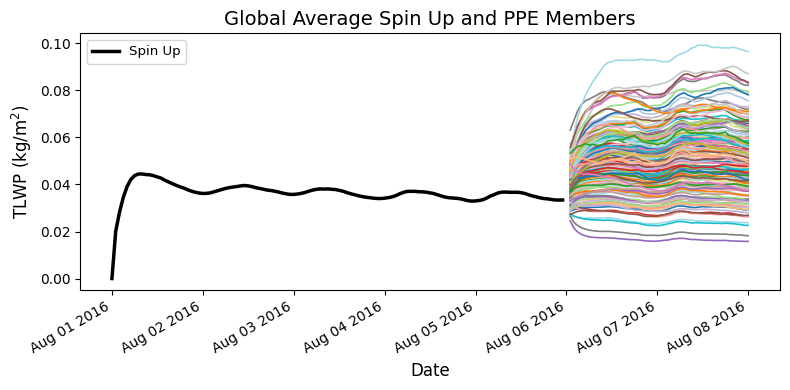

In [39]:
for v in range(num_var):
   tvar = var[v]
   date_list, global_list = date_list_all[tvar], global_list_all[tvar]

   fig, ax = plt.subplots(figsize=(8, 4))
   for c in range(num_case):
      if len(date_list[c]) == 0: continue
      tlabel = case_name[c] if case_name[c] != '' else '_nolegend_'
      ax.plot(date_list[c], global_list[c], color=clr[c],
              linestyle=dash_to_linestyle(dsh[c]),
              linewidth=lwd[c] if lwd[c] is not None else line_thickness,
              label=tlabel, zorder=10 if tlabel != '_nolegend_' else 1)
   ax.set_xlabel('Date', fontsize=label_font_size)
   #ax.set_ylabel(var_str[v], fontsize=label_font_size)
   ax.set_ylabel('TLWP (kg/m$^2$)', fontsize=label_font_size)
   ax.set_title(f'Global Average Spin Up and PPE Members', fontsize=title_font_size)
   ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %Y')) #'%m-%d-%Y'))
   for lbl in ax.get_xticklabels(): lbl.set_rotation(30); lbl.set_ha('right')
   #ax.grid(True, alpha=0.3)
   if any(n != '' for n in case_name): ax.legend(fontsize=label_font_size * 0.8)
   fig.tight_layout()
   fig.savefig(f'{fig_dir}/{tvar}_global.{fig_type}', dpi=150, bbox_inches='tight')
   plt.show()


## 2) Regional average plots - one panel per region

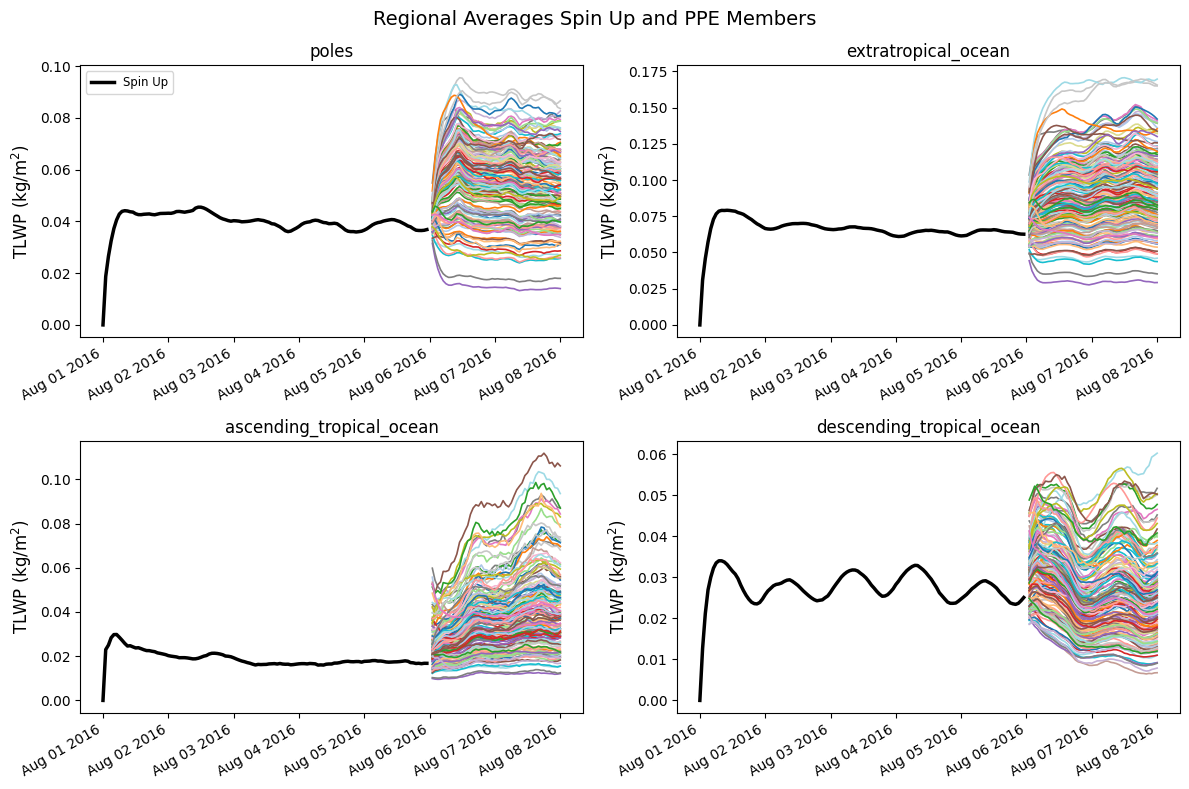

In [38]:
exclude_regions = {'tropical_land', 'extratropical_land'}

for v in range(num_var):
   tvar = var[v]
   date_list, regional_list = date_list_all[tvar], regional_list_all[tvar]

   plot_regions = [r for r in regions_list if r not in exclude_regions]
   ncols = 2 #min(3, len(plot_regions))
   nrows = 2 #int(np.ceil(len(plot_regions) / ncols)) if plot_regions else 1
   fig, axs = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), squeeze=False)
   axs = axs.flatten()
   for i, reg_name in enumerate(plot_regions):
      ax = axs[i]
      for c in range(num_case):
         if regional_list[c].empty: continue
         tlabel = case_name[c] if case_name[c] != '' else '_nolegend_'
         ax.plot(date_list[c], regional_list[c][reg_name], color=clr[c],
                 linestyle=dash_to_linestyle(dsh[c]),
                 linewidth=lwd[c] if lwd[c] is not None else line_thickness,
                 label=tlabel, zorder=10 if tlabel != '_nolegend_' else 1)
      ax.set_title(reg_name, fontsize=label_font_size)
      ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %Y'))
      ax.set_ylabel('TLWP (kg/m$^2$)', fontsize=label_font_size)
      for lbl in ax.get_xticklabels(): lbl.set_rotation(30); lbl.set_ha('right')
      #ax.grid(True, alpha=0.3)
   for ax in axs[len(plot_regions):]: ax.set_visible(False)
   fig.suptitle('Regional Averages Spin Up and PPE Members', fontsize=title_font_size)
   if any(n != '' for n in case_name): axs[0].legend(fontsize=label_font_size * 0.7)
   fig.tight_layout()
   fig.savefig(f'{fig_dir}/{tvar}_regional.{fig_type}', dpi=300, bbox_inches='tight')
   plt.show()

## 3) Zonal average plots - one panel per 10-degree latitude band, all cases overlaid

(A per-case Hovmoller grid isn't practical with ~100 PPE members, so this uses the same spaghetti style as the global/regional plots.)

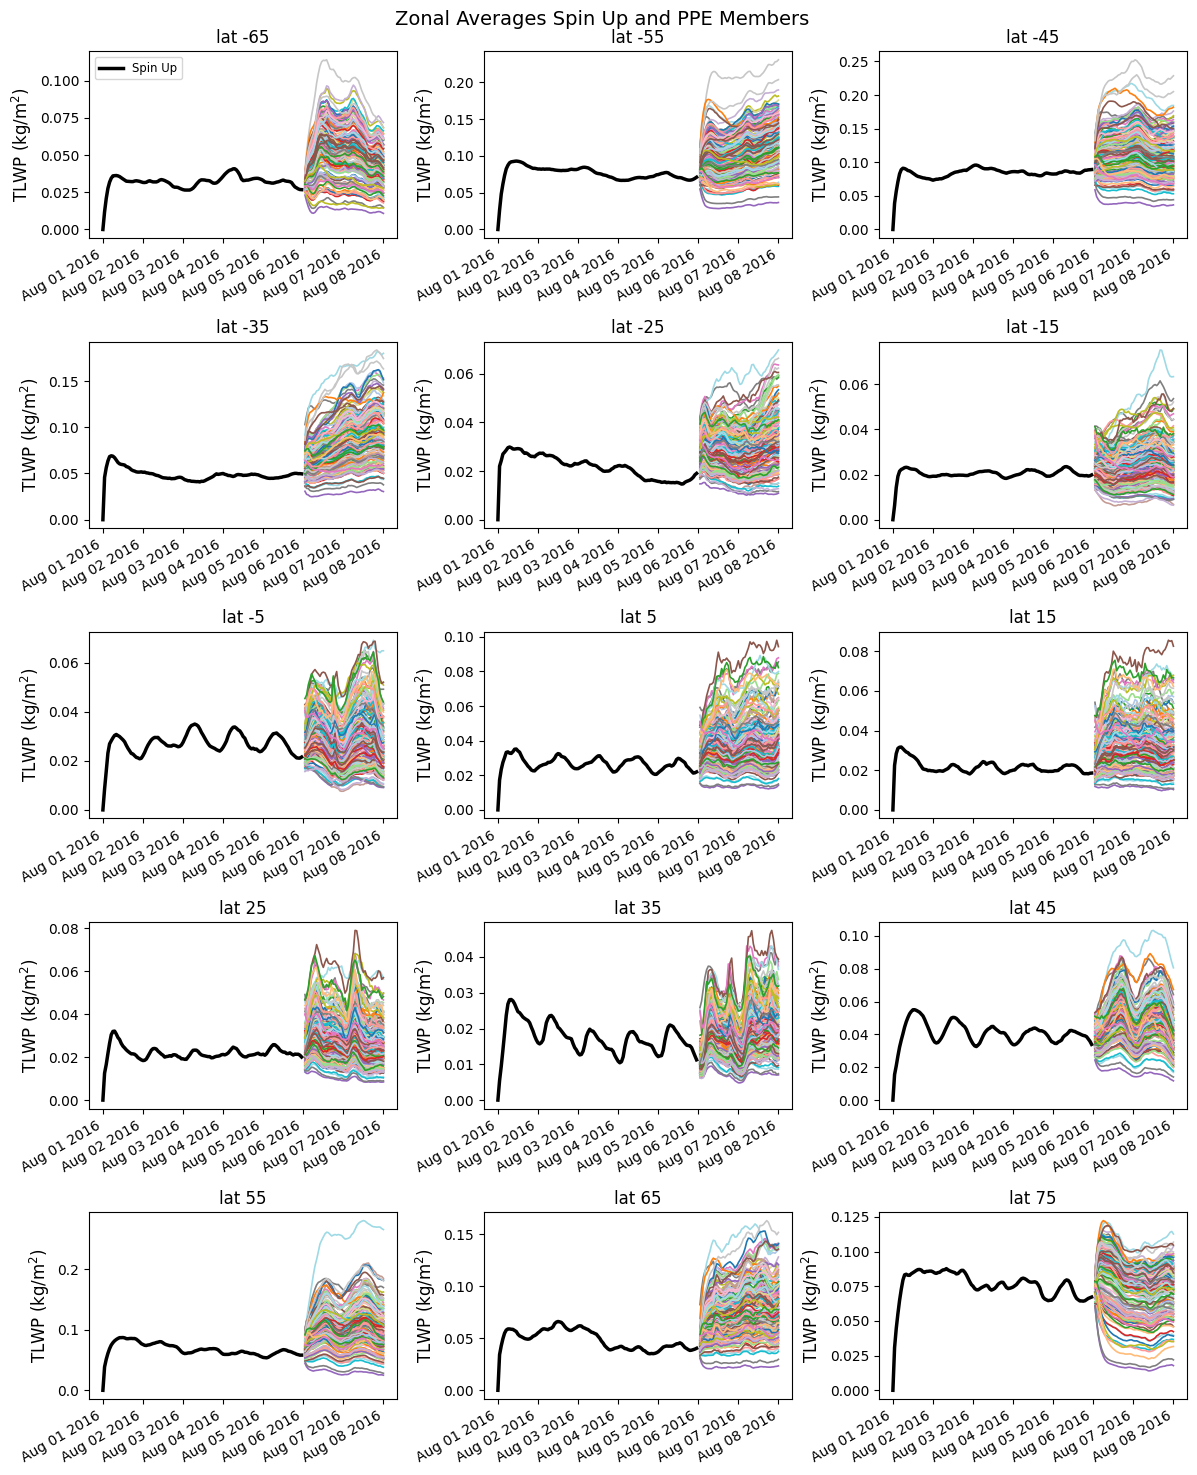

In [40]:
exclude_zone_centers = {-85, -75, 85}

for v in range(num_var):
   tvar = var[v]
   date_list, zonal_list = date_list_all[tvar], zonal_list_all[tvar]

   zone_centers = [zc for zc in zonal_list[0].columns if zc not in exclude_zone_centers] if not zonal_list[0].empty else []
   ncols = 3 #6
   nrows = 5 #int(np.ceil(len(zone_centers) / ncols)) if zone_centers else 1
   fig, axs = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)
   axs = axs.flatten()
   for i, zc in enumerate(zone_centers):
      ax = axs[i]
      for c in range(num_case):
         if zonal_list[c].empty: continue
         tlabel = case_name[c] if case_name[c] != '' else '_nolegend_'
         ax.plot(date_list[c], zonal_list[c][zc], color=clr[c],
                 linestyle=dash_to_linestyle(dsh[c]),
                 linewidth=lwd[c] if lwd[c] is not None else line_thickness,
                 label=tlabel, zorder=10 if tlabel != '_nolegend_' else 1)
      ax.set_title(f'lat {zc:.0f}', fontsize=label_font_size)
      ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %Y'))
      ax.set_ylabel('TLWP (kg/m$^2$)', fontsize=label_font_size)
      for lbl in ax.get_xticklabels(): lbl.set_rotation(30); lbl.set_ha('right')
      #ax.grid(True, alpha=0.3)
   for ax in axs[len(zone_centers):]: ax.set_visible(False)
   fig.suptitle('Zonal Averages Spin Up and PPE Members', fontsize=title_font_size)
   if any(n != '' for n in case_name): axs[0].legend(fontsize=label_font_size * 0.7)
   fig.tight_layout()
   fig.savefig(f'{fig_dir}/{tvar}_zonal.{fig_type}', dpi=300, bbox_inches='tight')
   plt.show()


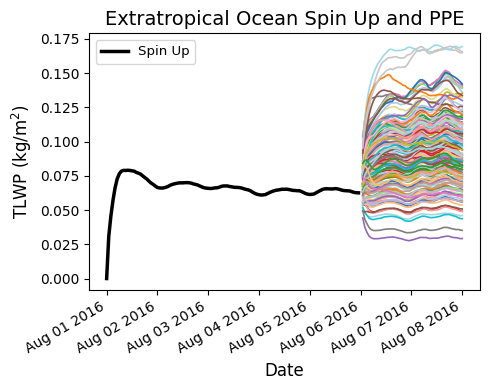

In [58]:
region_to_plot = 'extratropical_ocean' #'poles'

for v in range(num_var):
   tvar = var[v]
   date_list, regional_list = date_list_all[tvar], regional_list_all[tvar]

   fig, ax = plt.subplots(figsize=(5, 4))
   for c in range(num_case):
      if regional_list[c].empty: continue
      tlabel = case_name[c] if case_name[c] != '' else '_nolegend_'
      ax.plot(date_list[c], regional_list[c][region_to_plot], color=clr[c],
              linestyle=dash_to_linestyle(dsh[c]),
              linewidth=lwd[c] if lwd[c] is not None else line_thickness,
              label=tlabel, zorder=10 if tlabel != '_nolegend_' else 1)
   ax.set_xlabel('Date', fontsize=label_font_size)
   #ax.set_ylabel(var_str[v], fontsize=label_font_size)
   ax.set_ylabel('TLWP (kg/m$^2$)', fontsize=label_font_size)
   #ax.set_title(f'{region_to_plot} Spin Up and PPE', fontsize=title_font_size)
   ax.set_title('Extratropical Ocean Spin Up and PPE', fontsize=title_font_size)
   ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %Y'))
   for lbl in ax.get_xticklabels(): lbl.set_rotation(30); lbl.set_ha('right')
   #ax.grid(True, alpha=0.3)
   if any(n != '' for n in case_name): ax.legend(fontsize=label_font_size * 0.8)
   fig.tight_layout()
   fig.savefig(f'{fig_dir}/{tvar}_region_{region_to_plot}.{fig_type}', dpi=150, bbox_inches='tight')
   plt.show()

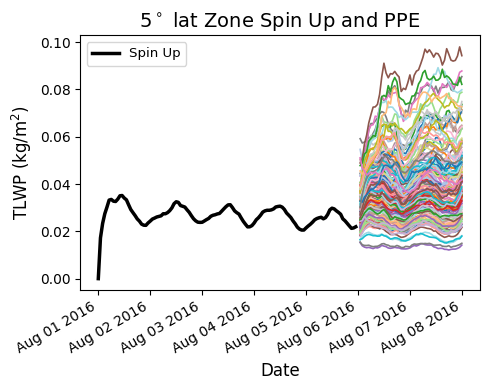

In [60]:
zone_to_plot = 5   # a value from zonal_list[0].columns (10-degree band center)

for v in range(num_var):
   tvar = var[v]
   date_list, zonal_list = date_list_all[tvar], zonal_list_all[tvar]

   fig, ax = plt.subplots(figsize=(5, 4))
   for c in range(num_case):
      if zonal_list[c].empty: continue
      tlabel = case_name[c] if case_name[c] != '' else '_nolegend_'
      ax.plot(date_list[c], zonal_list[c][zone_to_plot], color=clr[c],
              linestyle=dash_to_linestyle(dsh[c]),
              linewidth=lwd[c] if lwd[c] is not None else line_thickness,
              label=tlabel, zorder=10 if tlabel != '_nolegend_' else 1)
   ax.set_xlabel('Date', fontsize=label_font_size)
   #ax.set_ylabel(var_str[v], fontsize=label_font_size)
   ax.set_ylabel('TLWP (kg/m$^2$)', fontsize=label_font_size)
   ax.set_title(f'{zone_to_plot:.0f}$^\circ$ lat Zone Spin Up and PPE', fontsize=title_font_size)
   ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %Y'))
   for lbl in ax.get_xticklabels(): lbl.set_rotation(30); lbl.set_ha('right')
   #ax.grid(True, alpha=0.3)
   if any(n != '' for n in case_name): ax.legend(fontsize=label_font_size * 0.8)
   fig.tight_layout()
   fig.savefig(f'{fig_dir}/{tvar}_zone_{zone_to_plot:.0f}.{fig_type}', dpi=150, bbox_inches='tight')
   plt.show()
